# Задача 3. Распространение и детектирование света

Фотон испущен из точки $\vec x=(x,y,z)$ в направлении $\vec n=(n_x,n_y,n_z)$. Нужно определить, попадёт ли он в какой-либо ФЭУ, и смоделировать отклик детектора на событие.

> Классы `Detector` (Задача 1) и `Source` (Задача 2) вынесены в модули `detector.py` и `source.py` рядом с ноутбуками (в `Detector` добавлены методы этой задачи), чтобы не копировать код из ноутбука в ноутбук.

**Упрощения:** нет рассеяния и поглощения в сцинтилляторе; фотон полностью поглощается, достигнув границы детектора.

## Часть 1. Алгоритм: попадёт ли фотон в ФЭУ

1. **Луч до стенки.** Луч $\vec x+t\vec n$, $t>0$. Из $|\vec x+t\vec n|^2=R^2$:
$$t^2+2(\vec x\cdot\vec n)\,t+(|\vec x|^2-R^2)=0 .$$
Источник внутри сферы $\Rightarrow$ свободный член $<0$ $\Rightarrow$ ровно один положительный корень
$$t=-(\vec x\cdot\vec n)+\sqrt{(\vec x\cdot\vec n)^2-|\vec x|^2+R^2}.$$
Точка выхода: $\vec p=\vec x+t\vec n$.
2. **Принадлежность ФЭУ.** Для $\vec p$ на сфере используем уже готовый метод `pmt_index` из Задачи 1 (угол до оси ближайшего ФЭУ $\le\alpha$).

**Почему этого достаточно** (а не нужно искать пересечение луча с самим плоским диском). Обод фотокатода лежит на сфере, поэтому диск вместе со сферической шапкой над ним ограничивает выпуклый сегмент. Луч, идущий изнутри детектора, может попасть в шапку, только пройдя через диск, и наоборот. Значит, «пересёк фотокатод» $\Leftrightarrow$ «вышел на сферу внутри шапки ФЭУ». Ниже это проверено независимым прямым расчётом пересечения луча с диском. Единственное ограничение — источник не должен лежать внутри такого сегмента (глубина сегмента $R(1-\cos\alpha)\approx 2.5$ мм у стенки).

Всё векторизовано по фотонам: `trace(origin, directions)` принимает сразу массив направлений `(M, 3)`.

In [1]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

from detector import Detector
from source import Source

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

det = Detector(R=2.0, N=40, r=0.10, a=0.5, seed=2024)
src = Source(Y=10_000, seed=2025)
print(det)
print(src)

print(inspect.getsource(Detector.intersect_sphere))
print(inspect.getsource(Detector.trace))

Detector(R=2.0 м, N=40, r=0.1 м, a=0.5; alpha=2.866°, покрытие=2.50%)
Source(Y=10_000 фотонов/МэВ)
    def intersect_sphere(self, origin, directions) -> np.ndarray:
        """Точки, в которых лучи origin + t*n (t > 0) выходят на поверхность детектора.

        origin     : (3,) — общий источник, либо (M, 3) — свой для каждого луча
        directions : (M, 3) единичные векторы
        Возвращает массив (M, 3).

        Решаем |o + t n|^2 = R^2:  t^2 + 2 (o.n) t + (|o|^2 - R^2) = 0.
        Источник внутри сферы => свободный член < 0 => ровно один положительный корень
        t = -(o.n) + sqrt((o.n)^2 - (|o|^2 - R^2)).
        """
        o = np.asarray(origin, dtype=float)
        d = np.asarray(directions, dtype=float)
        if np.any(np.sum(o * o, axis=-1) >= self.R**2):
            raise ValueError("Источник должен находиться внутри детектора")
        b = np.sum(o * d, axis=-1)                            # (M,)
        c = np.sum(o * o, axis=-1) - self.R**2                # () ил

### Проверка алгоритма

In [2]:
def random_points_inside(n, rho_max, rng):
    """n точек, равномерно по объёму шара радиуса rho_max."""
    v = rng.normal(size=(n, 3))
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    return v * (rho_max * rng.uniform(size=(n, 1)) ** (1 / 3))


def trace_explicit_disk(det, origin, dirs):
    """Независимая проверка: прямое пересечение луча с плоским кругом каждого ФЭУ."""
    n = det.pmt_dirs                                    # (N, 3)
    c = det.R * np.cos(det.alpha) * n                   # центры фотокатодов
    dn = dirs @ n.T                                     # (M, N)  d . n_i
    with np.errstate(divide='ignore', invalid='ignore'):
        t = np.sum((c - origin) * n, axis=1)[None, :] / dn   # (M, N)
    q = origin[None, None, :] + t[:, :, None] * dirs[:, None, :]
    dist = np.linalg.norm(q - c[None, :, :], axis=2)
    hit = (dn > 0) & (t > 0) & (dist <= det.r)
    return np.where(hit.any(axis=1), hit.argmax(axis=1), -1)


rng = np.random.default_rng(0)

def test_exit_points_on_sphere():
    o = random_points_inside(1000, 0.95 * det.R, rng)
    d = Source(seed=1).random_directions(1000)
    p = det.intersect_sphere(o, d)
    assert np.allclose(np.linalg.norm(p, axis=1), det.R)
    # точка выхода лежит на луче впереди источника
    t = np.sum((p - o) * d, axis=1)
    assert np.all(t > 0) and np.allclose(o + t[:, None] * d, p)

def test_matches_explicit_disk_intersection():
    # источник дальше от стенки, чем глубина сегмента ФЭУ
    for _ in range(5):
        o = random_points_inside(1, 0.95 * det.R, rng)[0]
        d = Source(seed=int(rng.integers(1e6))).random_directions(40_000)
        a = det.trace(o, d)
        b = trace_explicit_disk(det, o, d)
        assert np.array_equal(a, b), np.sum(a != b)

def test_ray_to_pmt_center_hits_that_pmt():
    o = random_points_inside(1, 0.9 * det.R, rng)[0]
    d = det.pmt_pos - o
    d /= np.linalg.norm(d, axis=1, keepdims=True)
    assert np.array_equal(det.trace(o, d), np.arange(det.N))

def test_ray_from_center_along_axis():
    assert np.array_equal(det.trace(np.zeros(3), det.pmt_dirs), np.arange(det.N))

def test_ray_between_pmts_misses():
    # направление в самую «далёкую» от всех ФЭУ точку сферы
    probe = Source(seed=7).random_directions(200_000)
    cosmax = (probe @ det.pmt_dirs.T).max(axis=1)
    far = probe[np.argmin(cosmax)]
    assert det.trace(np.zeros(3), far[None, :])[0] == -1

def test_source_must_be_inside():
    try:
        det.trace(np.array([0, 0, 2.5]), np.array([[0, 0, 1.0]]))
    except ValueError:
        return
    raise AssertionError("Ожидалось ValueError")

def test_hit_fraction_from_center():
    n = 400_000
    d = Source(seed=11).random_directions(n)
    frac = np.mean(det.trace(np.zeros(3), d) >= 0)
    sigma = np.sqrt(det.coverage * (1 - det.coverage) / n)
    assert abs(frac - det.coverage) < 5 * sigma, (frac, det.coverage)

def test_photoelectrons_poisson():
    k = det.photoelectrons(np.ones(400_000, dtype=int))          # по одному фотону
    assert abs(k.mean() - det.a) < 5 * np.sqrt(det.a / k.size)
    assert abs(k.var() / det.a - 1) < 0.02                         # var = mean
    assert abs(np.mean(k == 0) - np.exp(-det.a)) < 0.005          # P(0) = e^{-a}
    assert np.all(k >= 0)

def test_photoelectrons_sum_is_poisson():
    k = det.photoelectrons(np.full(200_000, 10))                  # 10 фотонов
    assert abs(k.mean() - 10 * det.a) < 5 * np.sqrt(10 * det.a / k.size)
    assert abs(k.var() / (10 * det.a) - 1) < 0.03

def test_detect_counts_consistent():
    d = Source(seed=3).random_directions(20_000)
    o = np.array([0.3, -0.2, 0.5])
    n_hits, charge = det.detect(o, d)
    assert n_hits.shape == charge.shape == (det.N,)
    assert n_hits.sum() == np.sum(det.trace(o, d) >= 0)
    assert np.all(charge >= 0)

for name, f in list(globals().items()):
    if name.startswith("test_") and callable(f):
        f()
        print("OK ", name)

OK  test_exit_points_on_sphere


OK  test_matches_explicit_disk_intersection
OK  test_ray_to_pmt_center_hits_that_pmt
OK  test_ray_from_center_along_axis
OK  test_ray_between_pmts_misses
OK  test_source_must_be_inside


OK  test_hit_fraction_from_center
OK  test_photoelectrons_poisson
OK  test_photoelectrons_sum_is_poisson
OK  test_detect_counts_consistent


## Часть 2. Число фотоэлектронов: метод и его класс

Число фотоэлектронов от одного фотона, попавшего на фотокатод, $\sim\mathrm{Pois}(a)$. Метод `photoelectrons(n_photons)` возвращает случайное число фотоэлектронов от `n_photons` фотонов (для одного фотона — ровно $\mathrm{Pois}(a)$; сумма $n$ независимых $\mathrm{Pois}(a)$ есть $\mathrm{Pois}(an)$, поэтому розыгрыш векторизован по ФЭУ без цикла).

**Метод принадлежит классу `Detector`.** Обоснование:

* **Параметр $a$ — свойство фотокатода/ФЭУ**, а не источника света и не фотона. Он задаётся при создании детектора (Задача 1: `Detector(R, N, r, a)`), и метод, который его использует, должен жить рядом с данными (инкапсуляция).
* **`Source` ничего не знает о ФЭУ**: его задача — только родить фотоны (число и направления). Если положить сюда отклик ФЭУ, источник будет зависеть от устройства детектора, и им нельзя будет пользоваться отдельно (например, с другим детектором).
* **Нет смысла делать метод у фотона/траектории**: фотон — это просто строка в массиве `(M, 3)`; отклик определяется тем, *на какой ФЭУ* он попал, а это знает детектор (`trace`).
* **Все ФЭУ одинаковы**, а их координаты хранятся не отдельными объектами, а массивом внутри `Detector`; поэтому «фотокатод» как отдельный класс сейчас избыточен. Если в будущем у ФЭУ появятся индивидуальные параметры (разное $a$, шум, пьедестал), естественно будет выделить класс `PMT` — метод переедет в него, а `Detector` будет его вызывать (в массиве $a_i$).
* **Цепочка ответственности получается чистой:** `Source` (фотоны) $\to$ `Detector.trace` (геометрия) $\to$ `Detector.photoelectrons` (отклик фотокатода) $\to$ `Detector.detect` (сборка по каналам).

> Замечание. В Задаче 1 $a$ описано как «вероятность выбить хотя бы один фотоэлектрон», в Задаче 3 — как среднее число фотоэлектронов Пуассона. Здесь $a$ — это среднее Пуассона (Задача 3); тогда вероятность хотя бы одного фотоэлектрона на фотон равна $1-e^{-a}\approx 0.39$ при $a=0.5$.

In [3]:
print(inspect.getsource(Detector.photoelectrons))
print(inspect.getsource(Detector.detect))

    def photoelectrons(self, n_photons=1):
        """Случайное число фотоэлектронов от n_photons фотонов, попавших на фотокатод.

        Один фотон даёт Poisson(a) фотоэлектронов; сумма n независимых Poisson(a)
        есть Poisson(a n), поэтому для массива n_photons (по ФЭУ) розыгрыш векторизован.
        """
        return self.rng.poisson(self.a * np.asarray(n_photons))

    def detect(self, origin, directions):
        """Отклик детектора на набор фотонов.

        Возвращает (n_hits, charge), оба формы (N,):
        число фотонов, попавших на фотокатод каждого ФЭУ, и число фотоэлектронов.
        """
        idx = self.trace(origin, directions)
        n_hits = np.bincount(idx[idx >= 0], minlength=self.N)
        return n_hits, self.photoelectrons(n_hits)



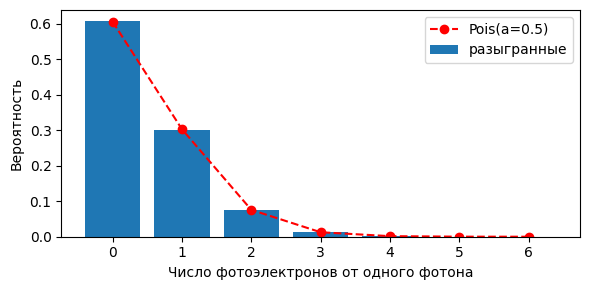

In [4]:
k = det.photoelectrons(np.ones(200_000, dtype=int))
vals, cnt = np.unique(k, return_counts=True)
from math import factorial

plt.bar(vals, cnt / k.size, label='разыгранные')
plt.plot(vals, [np.exp(-det.a) * det.a**m / factorial(m) for m in vals], 'ro--', label=f'Pois(a={det.a})')
plt.xlabel('Число фотоэлектронов от одного фотона'); plt.ylabel('Вероятность'); plt.legend()
plt.show()

## Часть 3. Событие 1 МэВ в центре детектора

Для одного события: `Source.generate(E)` $\to$ `Detector.detect(origin, directions)` $\to$ заряд по каналам; полный собранный заряд $Q=\sum_i q_i$.

In [5]:
E = 1.0                       # МэВ
origin = np.zeros(3)          # центр детектора

dirs = src.generate(E)
n_hits, charge = det.detect(origin, dirs)

print(f"Фотонов испущено:                {len(dirs)}")
print(f"Попало на фотокатоды:            {n_hits.sum()}")
print(f"Полный собранный заряд Q:        {charge.sum()} фотоэлектронов")
print(f"Каналов с ненулевым зарядом:     {np.count_nonzero(charge)} из {det.N}")

Фотонов испущено:                10107
Попало на фотокатоды:            262
Полный собранный заряд Q:        162 фотоэлектронов
Каналов с ненулевым зарядом:     39 из 40


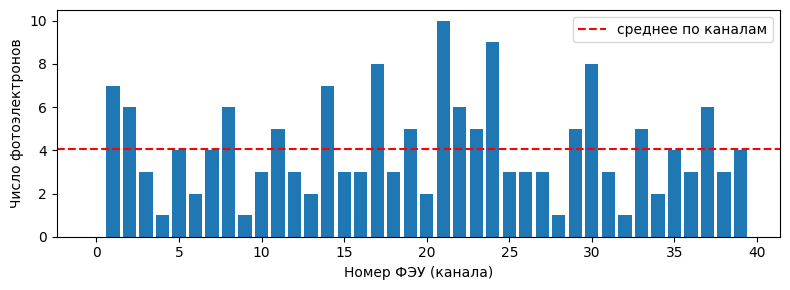

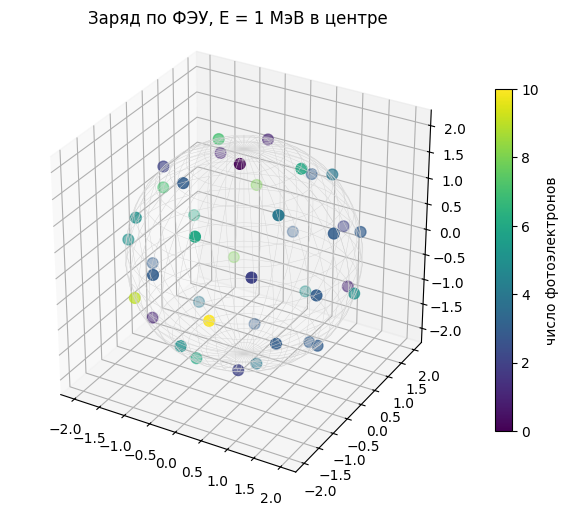

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(det.N), charge)
ax.axhline(charge.sum() / det.N, color='r', ls='--', label='среднее по каналам')
ax.set_xlabel('Номер ФЭУ (канала)'); ax.set_ylabel('Число фотоэлектронов'); ax.legend()
plt.show()

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection='3d')
u, w = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(det.R*np.cos(u)*np.sin(w), det.R*np.sin(u)*np.sin(w), det.R*np.cos(w),
                  color='lightgray', linewidth=0.3)
sc = ax.scatter(*det.pmt_pos.T, c=charge, s=60, cmap='viridis')
fig.colorbar(sc, ax=ax, shrink=0.6, label='число фотоэлектронов')
ax.set_box_aspect((1, 1, 1)); ax.set_title('Заряд по ФЭУ, E = 1 МэВ в центре')
plt.show()

### Сравнение с ожидаемым $Q = a\,Y\,\dfrac{N r^2}{R^2}$

Для одного события заряд — случайная величина, поэтому сравнивать нужно со средним по многим событиям (и учитывать разброс).

In [7]:
Q_task = det.a * src.Y * E * det.N * det.r**2 / det.R**2        # формула из условия
print(f"Q по формуле из условия, a*Y*(N r^2/R^2):  {Q_task:.1f}")
print(f"Q (одно событие, выше):                    {charge.sum()}")

n_events = 3000
Q = np.array([det.detect(origin, src.generate(E))[1].sum() for _ in range(n_events)])
print(f"Q (среднее по {n_events} событиям):          {Q.mean():.2f} ± {Q.std(ddof=1)/np.sqrt(n_events):.2f}")
print(f"Отношение к формуле из условия:            {Q.mean() / Q_task:.3f}")

Q по формуле из условия, a*Y*(N r^2/R^2):  500.0
Q (одно событие, выше):                    162


Q (среднее по 3000 событиям):          125.07 ± 0.25
Отношение к формуле из условия:            0.250


**Результат: моделирование даёт $Q\approx 125$, то есть в 4 раза меньше, чем $500$ по формуле из условия.** Это не ошибка моделирования, а особенность формулы. Изотропный источник в центре освещает ФЭУ в доле телесного угла

$$f=\frac{\Omega_{\text{PMT}}}{4\pi}=\frac{1-\cos\alpha}{2}\approx\frac{\alpha^2}{4}\approx\frac{r^2}{4R^2}\qquad(\sin\alpha=r/R),$$

то есть площадь фотокатода $\pi r^2$ надо делить на площадь **всей сферы $4\pi R^2$**, а не на $\pi R^2$. Поэтому правильная оценка
$$Q=a\,Y\,E\cdot N\,\frac{1-\cos\alpha}{2}\;\approx\;a\,Y\,E\,\frac{N r^2}{4R^2},$$
и формула из условия завышает результат ровно в 4 раза (в ней забыт множитель $1/4$; он получится, если принять за долю отношение площади диска к площади *большого круга* $\pi R^2$, а не к площади сферы).

Q точная геометрия, a Y N (1-cos α)/2:     125.08
Q малые углы, a Y N r²/(4R²):              125.00
Q моделирование (среднее):                 125.07 ± 0.25
Отношение моделирования к формуле из условия: 0.250 (ожидается 0.25)
sigma(Q): моделирование 13.63, ожидается sqrt(187.6) = 13.70


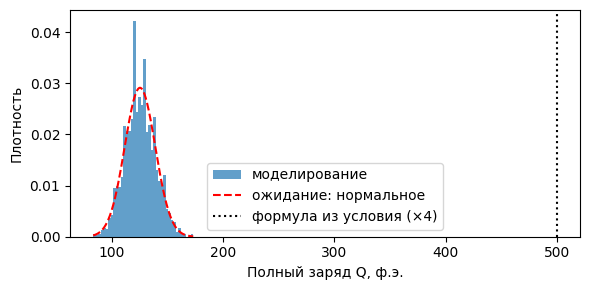

In [8]:
Q_exact = det.a * src.Y * E * det.coverage              # a*Y*E*N*(1-cos alpha)/2
Q_small = Q_task / 4                                   # a*Y*E*N*r^2/(4R^2)
print(f"Q точная геометрия, a Y N (1-cos α)/2:     {Q_exact:.2f}")
print(f"Q малые углы, a Y N r²/(4R²):              {Q_small:.2f}")
print(f"Q моделирование (среднее):                 {Q.mean():.2f} ± {Q.std(ddof=1)/np.sqrt(n_events):.2f}")
print(f"Отношение моделирования к формуле из условия: {Q.mean()/Q_task:.3f} (ожидается 0.25)")

# ширина распределения: Q = Pois(a*H), H ~ Pois(Y E f)  =>  Var = a*mu_H + a^2*mu_H
mu_H = src.Y * E * det.coverage
var_expected = det.a * mu_H + det.a**2 * mu_H
print(f"sigma(Q): моделирование {Q.std(ddof=1):.2f}, ожидается sqrt({var_expected:.1f}) = {np.sqrt(var_expected):.2f}")

plt.hist(Q, bins=40, density=True, alpha=0.7, label='моделирование')
x = np.linspace(Q.min(), Q.max(), 300)
plt.plot(x, np.exp(-0.5*((x-Q_exact)/np.sqrt(var_expected))**2)/np.sqrt(2*np.pi*var_expected),
         'r--', label='ожидание: нормальное')
plt.axvline(Q_task, color='k', ls=':', label='формула из условия (×4)')
plt.xlabel('Полный заряд Q, ф.э.'); plt.ylabel('Плотность'); plt.legend()
plt.show()

## Выводы

* **Алгоритм попадания фотона в ФЭУ:** пересечение луча со сферой (квадратное уравнение) + проверка угла до ближайшей оси ФЭУ. Векторизован, подтверждён независимым расчётом пересечения луча с диском фотокатода и тестами (в т. ч. источник вне центра).
* **Метод `photoelectrons`** (Пуассон со средним $a$) принадлежит классу **`Detector`**: $a$ — параметр фотокатода, `Source` о ФЭУ ничего знать не должен.
* **Событие 1 МэВ в центре:** собранный заряд $Q\approx 125$ ф.э. (среднее по событиям; разброс $\sigma\approx 14$, как и предсказывает составной пуассоновский процесс). Это согласуется с геометрическим ожиданием $a\,Y\,N(1-\cos\alpha)/2$, но **в 4 раза меньше**, чем $a\,Y\,N r^2/R^2$ из условия — из-за отсутствия множителя $1/4$ (отношение площади фотокатода к площади всей сферы $4\pi R^2$).